 # **House Price Prediction**

## 1. Imports & Configuration

### Project Overview

House Price Prediction is a supervised machine learning regression project. The objective of this project is to predict the selling price of a house based on different property-related features.

The dataset contains information about the physical characteristics, quality, size, condition, garage, basement, neighborhood, and other attributes of houses.

### Project Objective

The main objectives of this project are:

* To understand the house price dataset.
* To identify and handle missing values.
* To correct inappropriate data types.
* To perform Exploratory Data Analysis (EDA).
* To identify important features related to house prices.
* To perform feature engineering and preprocessing.
* To build multiple regression models.
* To evaluate and compare model performance.
* To tune suitable machine learning models.
* To select the best-performing model for house price prediction.

### Libraries Used

The project uses NumPy and Pandas for data manipulation, Matplotlib and Seaborn for visualization, and Scikit-learn for preprocessing, model building, evaluation, and hyperparameter tuning.

XGBoost and LightGBM are also used as advanced tree-based regression algorithms.

### Configuration

The project uses a test size of 20%, a random state of 42, and a skewness threshold of 0.75.

These configuration values are kept in one place so that the same settings can be used consistently throughout the project.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import PowerTransformer, RobustScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="darkgrid")
pd.set_option("display.max_columns", None)

CONFIG = {
    "data_path": "/content/data.csv",
    "test_size": 0.2,
    "random_state": 42,
    "skew_threshold": 0.75,
}

## 2. Load Data

In [ ]:
raw = pd.read_csv(CONFIG["data_path"])
raw = raw.drop(columns=["Id"])
print(f"Shape: {raw.shape}")
raw.head()

Shape: (1460, 80)


,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [ ]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 80 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   MSSubClass     1460 non-null   int64  
 1   MSZoning       1460 non-null   object 
 2   LotFrontage    1201 non-null   float64
 3   LotArea        1460 non-null   int64  
 4   Street         1460 non-null   object 
 5   Alley          91 non-null     object 
 6   LotShape       1460 non-null   object 
 7   LandContour    1460 non-null   object 
 8   Utilities      1460 non-null   object 
 9   LotConfig      1460 non-null   object 
 10  LandSlope      1460 non-null   object 
 11  Neighborhood   1460 non-null   object 
 12  Condition1     1460 non-null   object 
 13  Condition2     1460 non-null   object 
 14  BldgType       1460 non-null   object 
 15  HouseStyle     1460 non-null   object 
 16  OverallQual    1460 non-null   int64  
 17  OverallCond    1460 non-null   int64  
 18  YearBuil

In [ ]:
missing_counts = raw.isna().sum()
missing_counts[missing_counts > 0].sort_values(ascending=False)

,0
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
MasVnrType,872
FireplaceQu,690
LotFrontage,259
GarageType,81
GarageYrBlt,81
GarageFinish,81


## 3. Missing Value Imputation

Columns are grouped by fill strategy in a small config dict, then each group is filled with a single `fillna()` call rather than one loop per column.

In [ ]:
# Columns where NaN genuinely means "feature absent"
none_fill_cols = [
    "PoolQC", "MiscFeature", "Alley", "Fence", "MasVnrType", "FireplaceQu",
    "GarageType", "GarageFinish", "GarageQual", "GarageCond",
    "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
]

df = raw.copy()
df[none_fill_cols] = df[none_fill_cols].fillna("None")

In [ ]:
# GarageYrBlt has no meaningful median when there is no garage at all
df["GarageYrBlt"] = df["GarageYrBlt"].fillna(0)

# Remaining numeric gaps get the column median
median_fill_cols = ["LotFrontage", "MasVnrArea"]
df[median_fill_cols] = df[median_fill_cols].fillna(df[median_fill_cols].median())

In [ ]:
# Any leftover categorical gaps (e.g. Electrical) filled with the column mode,
# built as a single dict and applied in one fillna() call
object_cols = df.select_dtypes("object").columns
mode_fill = {c: df[c].mode(dropna=True).iat[0] for c in object_cols if df[c].isna().any()}
df = df.fillna(mode_fill)

assert df.isna().sum().sum() == 0, "Unresolved missing values remain"
print("All missing values resolved.")

All missing values resolved.


## 4. Data Type Corrections

Correct data types are important because machine learning algorithms process numerical and categorical variables differently.

The `MSSubClass` feature represents a coded housing classification rather than a continuous numerical measurement. Therefore, it is converted to a categorical data type.

The remaining object-type columns are also converted to categorical data types.

This makes the dataset more appropriate for the later encoding and preprocessing steps.

After conversion, the distribution of data types is checked to confirm the changes.


In [ ]:
# MSSubClass is a coded rating (20-190), not a continuous quantity
df["MSSubClass"] = df["MSSubClass"].astype("category")

object_cols = df.select_dtypes("object").columns
df[object_cols] = df[object_cols].astype("category")
df.dtypes.value_counts()

,count
int64,33
float64,3
category,3
category,2
category,2
category,2
category,1
category,1
category,1
category,1


## 5. Train / Test Split

Split happens **before** any statistic-derived preprocessing (skew correction, scaling), so nothing about the test set leaks into training-time statistics.

In [ ]:
features = df.drop(columns=["SalePrice"])
target = np.log1p(df["SalePrice"])  # model on log scale throughout

X_train, X_test, y_train, y_test = train_test_split(
    features, target,
    test_size=CONFIG["test_size"],
    random_state=CONFIG["random_state"],
)
print(f"Train: {X_train.shape}  |  Test: {X_test.shape}")

Train: (1168, 79)  |  Test: (292, 79)


## 6. Exploratory Data Analysis

Exploratory Data Analysis (EDA) is performed to understand the distribution of house prices and identify relationships between different features and the target variable.

The analysis is performed using the training data.

### 6.1 SalePrice Distribution

The distribution and spread of `SalePrice` are visualized using a histogram and boxplot.

The training data contains **1,168 observations**.

The house prices range from **$34,900 to $745,000**.

### 6.2 Correlation Analysis

Correlation between numerical features and `SalePrice` is calculated.

Features having an absolute correlation of at least **0.5** are considered strongly correlated with the target for this analysis.

The important correlated features include:

* OverallQual
* GrLivArea
* GarageCars
* GarageArea
* TotalBsmtSF
* 1stFlrSF
* FullBath
* TotRmsAbvGrd
* YearBuilt
* YearRemodAdd

Among these, `OverallQual` has the strongest correlation with `SalePrice`.

### 6.3 Feature Relationship Visualization

Selected features are visualized against `SalePrice` using boxplots and scatterplots to understand their relationship with house prices.

### 6.4 Outlier Analysis

A Z-score based check is used to identify potential outliers in the house price distribution.

Using the threshold of |z| > 3, **17 potential outliers** are identified out of 1,168 training observations.

These observations are identified for analysis rather than automatically removed.


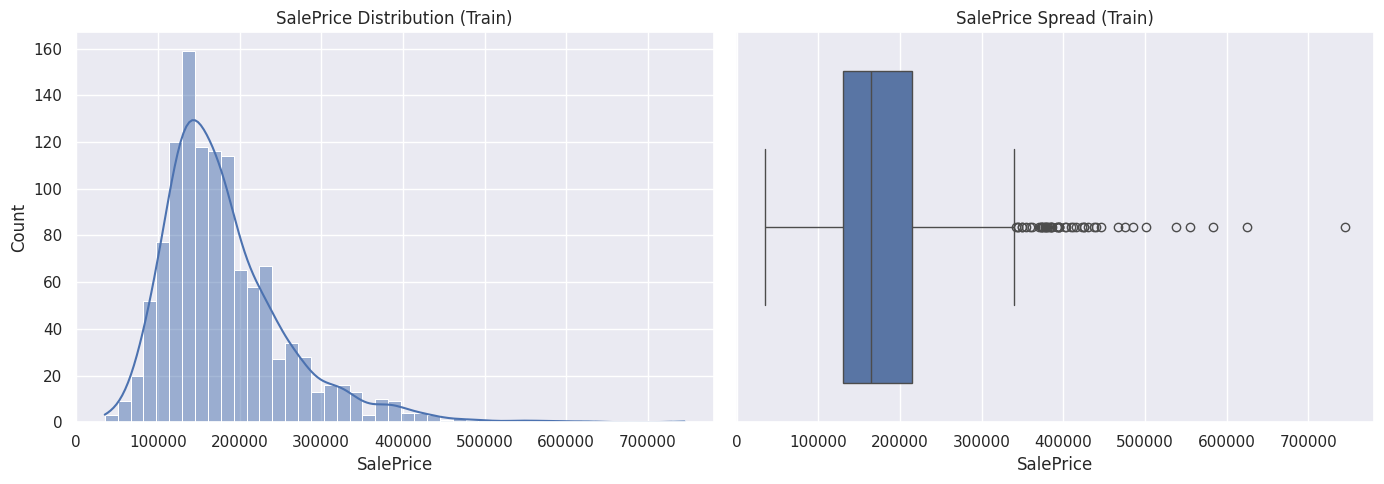

,SalePrice
count,1168.000000
mean,181441.541952
std,77263.583862
min,34900.000000
25%,130000.000000
50%,165000.000000
75%,214925.000000
max,745000.000000


In [ ]:
train_price = np.expm1(y_train)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(train_price, kde=True, ax=axes[0])
axes[0].set_title("SalePrice Distribution (Train)")
sns.boxplot(x=train_price, ax=axes[1])
axes[1].set_title("SalePrice Spread (Train)")
plt.tight_layout()
plt.show()

train_price.describe()

In [ ]:
numeric_train = X_train.select_dtypes(include=np.number).copy()
numeric_train["SalePrice"] = train_price

corr_with_price = numeric_train.corr()["SalePrice"].drop("SalePrice")

# Actually apply the >= 0.5 threshold rather than just taking head(N)
strong_corr = corr_with_price[corr_with_price.abs() >= 0.5].sort_values(ascending=False)
print(f"{len(strong_corr)} features correlate with SalePrice at |r| >= 0.5:")
strong_corr

10 features correlate with SalePrice at |r| >= 0.5:


,SalePrice
OverallQual,0.785555
GrLivArea,0.695652
GarageCars,0.640991
GarageArea,0.624139
TotalBsmtSF,0.597766
1stFlrSF,0.587883
FullBath,0.552546
TotRmsAbvGrd,0.520388
YearBuilt,0.516501
YearRemodAdd,0.508593


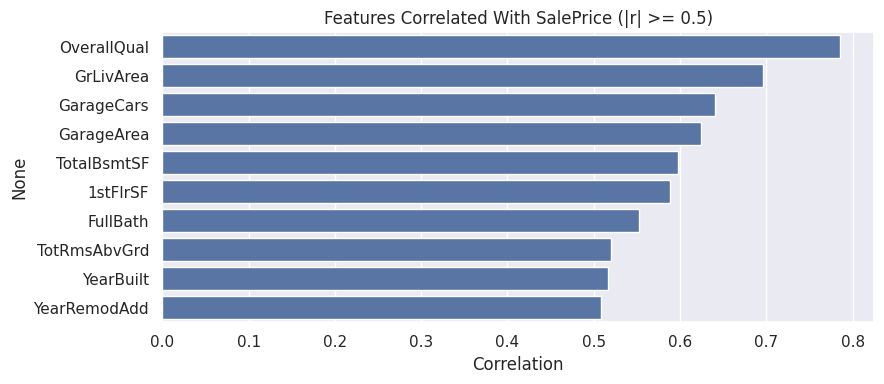

In [ ]:
plt.figure(figsize=(9, max(4, 0.35 * len(strong_corr))))
sns.barplot(x=strong_corr.values, y=strong_corr.index, orient="h")
plt.title("Features Correlated With SalePrice (|r| >= 0.5)")
plt.xlabel("Correlation")
plt.tight_layout()
plt.show()

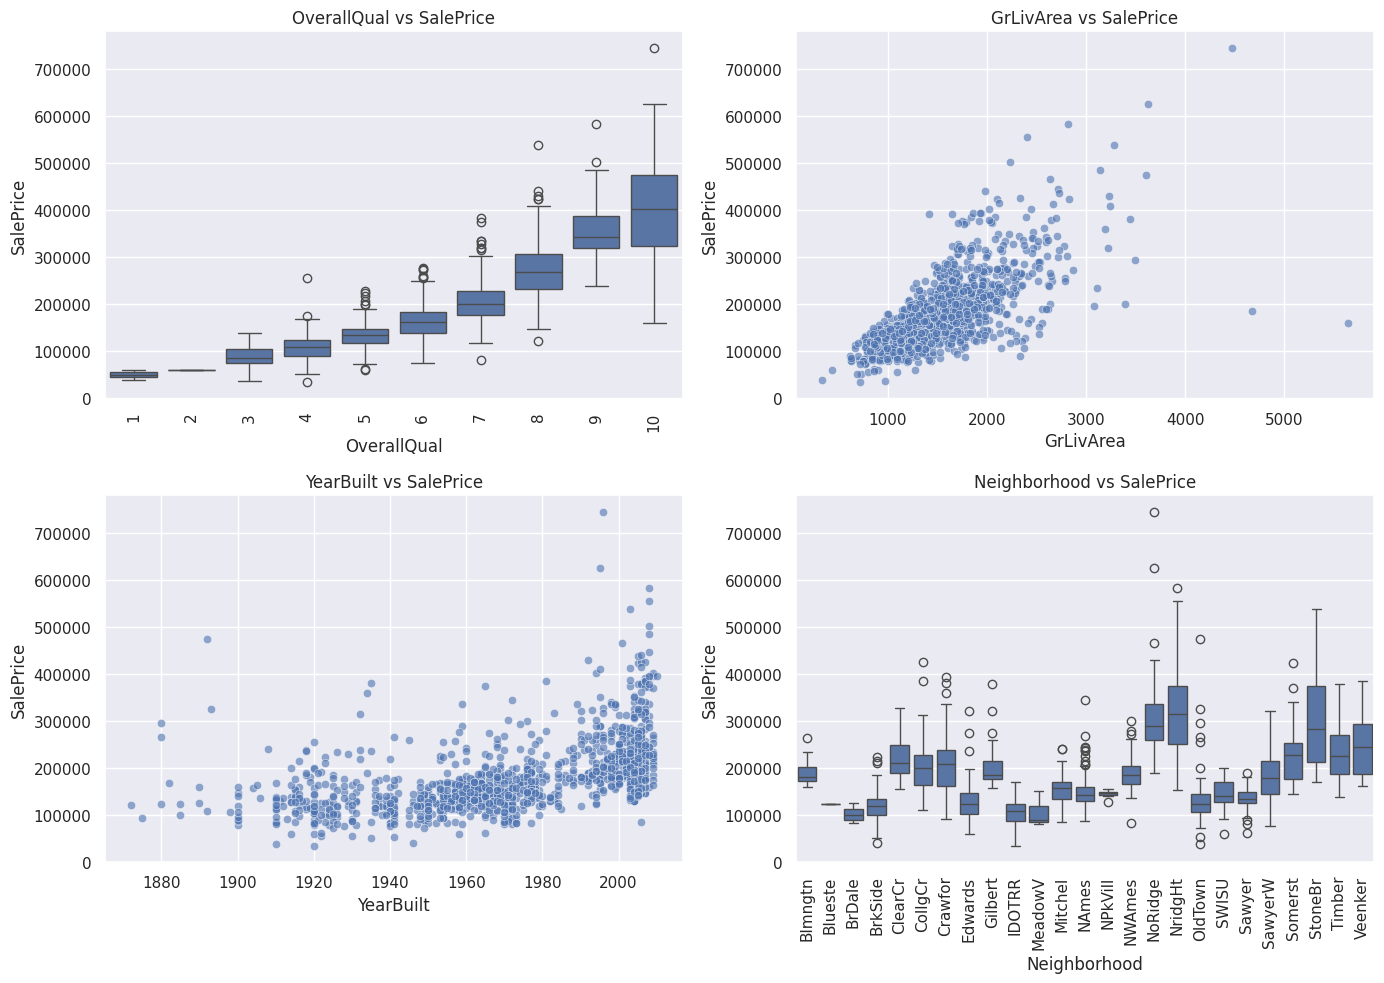

In [ ]:
# Loop over a small set of (column, plot type) pairs instead of one
# hand-written cell per chart
feature_plots = [
    ("OverallQual", "box"),
    ("GrLivArea", "scatter"),
    ("YearBuilt", "scatter"),
    ("Neighborhood", "box"),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
plot_df = X_train.copy()
plot_df["SalePrice"] = train_price

for ax, (col, kind) in zip(axes.ravel(), feature_plots):
    if kind == "box":
        sns.boxplot(data=plot_df, x=col, y="SalePrice", ax=ax)
        if plot_df[col].nunique() > 8:
            ax.tick_params(axis="x", rotation=90)
    else:
        sns.scatterplot(data=plot_df, x=col, y="SalePrice", ax=ax, alpha=0.6)
    ax.set_title(f"{col} vs SalePrice")

plt.tight_layout()
plt.show()

In [ ]:
# Z-score outlier check instead of IQR
z_scores = (train_price - train_price.mean()) / train_price.std()
outliers = train_price[z_scores.abs() > 3]
print(f"Potential outliers (|z| > 3): {len(outliers)} of {len(train_price)} rows")

Potential outliers (|z| > 3): 17 of 1168 rows


## 7. Feature Engineering

Feature engineering and preprocessing are performed to convert the dataset into a format suitable for machine learning algorithms.

The dataset contains both ordinal and nominal categorical variables.

### 7.1 Ordinal Encoding

Ordinal features have categories with a meaningful order.

For example, quality-related categories such as:

`Po < Fa < TA < Gd < Ex`

are converted into ordered numerical values.

An explicit ordered `CategoricalDtype` is used and the categories are converted into numerical codes.

### 7.2 Nominal Encoding

Nominal categorical variables do not have a natural order.

These variables are converted into numerical representation using one-hot encoding with `pd.get_dummies()`.

The test dataset is reindexed so that training and testing data contain exactly the same columns.

### 7.3 Skewness Correction

Numerical features are checked for skewness.

A skewness threshold of **0.75** is used.

Features exceeding this threshold are transformed using the **Yeo-Johnson Power Transformation**.

The transformation is fitted only on the training data and then applied to the test data.

### 7.4 Feature Scaling

`RobustScaler` is applied to the processed features.

Robust scaling is useful because it is less sensitive to extreme values and outliers.

The final training and testing datasets contain **276 features**.


In [ ]:
from pandas.api.types import CategoricalDtype

quality_scale = ["Po", "Fa", "TA", "Gd", "Ex"]
quality_scale_with_none = ["None"] + quality_scale

ordinal_map = {
    "ExterQual": quality_scale,
    "ExterCond": quality_scale,
    "HeatingQC": quality_scale,
    "KitchenQual": quality_scale,
    "BsmtQual": quality_scale_with_none,
    "BsmtCond": quality_scale_with_none,
    "FireplaceQu": quality_scale_with_none,
    "GarageQual": quality_scale_with_none,
    "GarageCond": quality_scale_with_none,
    "PoolQC": ["None", "Fa", "Gd", "Ex"],
}
ordinal_cols = [c for c in ordinal_map if c in X_train.columns]

def encode_ordinal(frame: pd.DataFrame) -> pd.DataFrame:
    frame = frame.copy()
    for col in ordinal_cols:
        cat_type = CategoricalDtype(categories=ordinal_map[col], ordered=True)
        frame[col] = frame[col].astype(str).astype(cat_type).cat.codes
    return frame

X_train_enc = encode_ordinal(X_train)
X_test_enc = encode_ordinal(X_test)

In [ ]:
nominal_cols = [
    c for c in X_train_enc.select_dtypes(include=["category", "object"]).columns
]

X_train_enc = pd.get_dummies(X_train_enc, columns=nominal_cols)
X_test_enc = pd.get_dummies(X_test_enc, columns=nominal_cols)

# Keep train/test columns identical; anything missing in test becomes 0
X_test_enc = X_test_enc.reindex(columns=X_train_enc.columns, fill_value=0)

print(f"Encoded train shape: {X_train_enc.shape}")
print(f"Encoded test shape:  {X_test_enc.shape}")

Encoded train shape: (1168, 276)
Encoded test shape:  (292, 276)


In [ ]:
numeric_cols = X_train.select_dtypes(include=np.number).columns.tolist()
train_skew = X_train_enc[numeric_cols].skew().abs()
skewed_cols = train_skew[train_skew > CONFIG["skew_threshold"]].index.tolist()
print(f"{len(skewed_cols)} numeric columns exceed skew threshold {CONFIG['skew_threshold']}")

power = PowerTransformer(method="yeo-johnson")
X_train_enc[skewed_cols] = power.fit_transform(X_train_enc[skewed_cols])
X_test_enc[skewed_cols] = power.transform(X_test_enc[skewed_cols])

21 numeric columns exceed skew threshold 0.75


In [ ]:
# RobustScaler applied uniformly (less sensitive to the outliers flagged above)
scaler = RobustScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train_enc), columns=X_train_enc.columns, index=X_train_enc.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test_enc), columns=X_test_enc.columns, index=X_test_enc.index
)
X_train_scaled.shape, X_test_scaled.shape

((1168, 276), (292, 276))

## 8. Model Training & Evaluation

One evaluation helper and one models dict — every model is fit and scored through the same loop instead of a separate cell per model.

In [ ]:
def evaluate(model, X_tr, y_tr, X_te, y_te) -> dict:
    model.fit(X_tr, y_tr)
    pred = np.expm1(model.predict(X_te))
    actual = np.expm1(y_te)
    return {
        "MAE": mean_absolute_error(actual, pred),
        "RMSE": np.sqrt(mean_squared_error(actual, pred)),
        "R2": r2_score(actual, pred),
    }

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=CONFIG["random_state"]),
    "Random Forest": RandomForestRegressor(
        n_estimators=300, random_state=CONFIG["random_state"], n_jobs=-1
    ),
}

In [ ]:
%pip install xgboost lightgbm -q

In [ ]:
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

models["XGBoost"] = XGBRegressor(
    n_estimators=300, learning_rate=0.05, max_depth=6,
    subsample=0.8, colsample_bytree=0.8,
    objective="reg:squarederror", random_state=CONFIG["random_state"], n_jobs=-1,
)
models["LightGBM"] = LGBMRegressor(
    n_estimators=300, learning_rate=0.05, num_leaves=31,
    subsample=0.8, colsample_bytree=0.8,
    random_state=CONFIG["random_state"], n_jobs=-1, verbosity=-1,
)

In [ ]:
baseline_rows = []
fitted_models = {}

for name, model in models.items():
    scores = evaluate(model, X_train_scaled, y_train, X_test_scaled, y_test)
    fitted_models[name] = model
    baseline_rows.append({"Model": name, "Tuned": False, **scores})
    print(f"{name:<20} MAE=${scores['MAE']:,.0f}  RMSE=${scores['RMSE']:,.0f}  R2={scores['R2']:.4f}")

baseline_df = pd.DataFrame(baseline_rows)

Linear Regression    MAE=$16,453  RMSE=$30,691  R2=0.8772
Decision Tree        MAE=$23,903  RMSE=$33,990  R2=0.8494
Random Forest        MAE=$17,308  RMSE=$29,498  R2=0.8866
XGBoost              MAE=$15,242  RMSE=$25,159  R2=0.9175
LightGBM             MAE=$16,109  RMSE=$28,343  R2=0.8953


## 9. Hyperparameter Tuning

Hyperparameter tuning is performed to improve the performance of the tree-based models.

The following models are tuned:

* Decision Tree
* Random Forest
* XGBoost
* LightGBM

`RandomizedSearchCV` is used to search through different combinations of hyperparameters.

The tuning process uses:

* **30 random parameter combinations**
* **5-fold cross-validation**
* **Negative RMSE** as the scoring metric

The best hyperparameters are selected based on the cross-validation search.

### Best Parameters

The tuned XGBoost model selected the following parameters:

* `n_estimators = 700`
* `learning_rate = 0.03`
* `max_depth = 4`
* `subsample = 0.7`
* `colsample_bytree = 1.0`

The tuned models are then evaluated on the separate test dataset.


In [ ]:
param_grids = {
    "Decision Tree": {
        "max_depth": [None, 5, 10, 15, 20, 25],
        "min_samples_split": [2, 5, 10, 15],
        "min_samples_leaf": [1, 2, 4, 8],
        "max_features": [None, "sqrt", "log2"],
    },
    "Random Forest": {
        "n_estimators": [200, 300, 400, 500],
        "max_depth": [None, 10, 20, 30],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf": [1, 2, 4],
        "max_features": [1.0, "sqrt", "log2"],
    },
    "XGBoost": {
        "n_estimators": [200, 300, 500, 700],
        "learning_rate": [0.01, 0.03, 0.05, 0.1],
        "max_depth": [3, 4, 5, 6, 8],
        "subsample": [0.7, 0.8, 0.9, 1.0],
        "colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    },
    "LightGBM": {
        "n_estimators": [200, 300, 500, 700],
        "learning_rate": [0.01, 0.03, 0.05, 0.1],
        "num_leaves": [15, 20, 31, 40],
        "subsample": [0.7, 0.8, 0.9, 1.0],
        "colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    },
}

In [ ]:
tuned_rows = []
best_models = {}

for name, grid in param_grids.items():
    search = RandomizedSearchCV(
        estimator=models[name],
        param_distributions=grid,
        n_iter=30,
        cv=5,
        scoring="neg_root_mean_squared_error",
        random_state=CONFIG["random_state"],
        n_jobs=-1,
    )
    search.fit(X_train_scaled, y_train)
    best_models[name] = search.best_estimator_

    scores = evaluate(search.best_estimator_, X_train_scaled, y_train, X_test_scaled, y_test)
    tuned_rows.append({"Model": f"Tuned {name}", "Tuned": True, **scores})
    print(f"Tuned {name:<20} best params: {search.best_params_}")

tuned_df = pd.DataFrame(tuned_rows)

Tuned Decision Tree        best params: {'min_samples_split': 15, 'min_samples_leaf': 8, 'max_features': None, 'max_depth': 10}
Tuned Random Forest        best params: {'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 1.0, 'max_depth': 30}
Tuned XGBoost              best params: {'subsample': 0.7, 'n_estimators': 700, 'max_depth': 4, 'learning_rate': 0.03, 'colsample_bytree': 1.0}
Tuned LightGBM             best params: {'subsample': 0.8, 'num_leaves': 20, 'n_estimators': 500, 'learning_rate': 0.03, 'colsample_bytree': 0.7}


## 10. Model Comparison

The baseline and tuned models are combined into a single results table and sorted according to RMSE.

The models are compared using:

* MAE
* RMSE
* R² Score

### Model Performance

| Model               |            MAE |           RMSE |         R² |
| ------------------- | -------------: | -------------: | ---------: |
| **Tuned XGBoost**   | **$14,593.53** | **$24,218.54** | **0.9235** |
| XGBoost             |     $15,241.51 |     $25,159.39 |     0.9175 |
| LightGBM            |     $16,108.70 |     $28,343.25 |     0.8953 |
| Tuned LightGBM      |     $15,692.29 |     $28,480.03 |     0.8943 |
| Tuned Random Forest |     $17,307.66 |     $29,497.53 |     0.8866 |
| Random Forest       |     $17,307.66 |     $29,497.53 |     0.8866 |
| Linear Regression   |     $16,453.18 |     $30,691.05 |     0.8772 |
| Decision Tree       |     $23,903.28 |     $33,990.25 |     0.8494 |
| Tuned Decision Tree |     $26,196.37 |     $40,430.63 |     0.7869 |

### Best Model

The **Tuned XGBoost Regressor** achieved the best overall performance.

Its performance is:

* **MAE:** $14,593.53
* **RMSE:** $24,218.54
* **R²:** 0.9235

An R² score of 0.9235 indicates that the model explains approximately **92.35% of the variation in house sale prices** on the test data.

Therefore, Tuned XGBoost is selected as the final model for this project.


In [ ]:
results = pd.concat([baseline_df, tuned_df], ignore_index=True)
results = results.sort_values("RMSE").reset_index(drop=True)
results

,Model,Tuned,MAE,RMSE,R2
0,Tuned XGBoost,True,14593.526193,24218.539965,0.923532
1,XGBoost,False,15241.514648,25159.391085,0.917475
2,LightGBM,False,16108.697218,28343.253346,0.895267
3,Tuned LightGBM,True,15692.291855,28480.025875,0.894253
4,Tuned Random Forest,True,17307.658922,29497.533338,0.886562
5,Random Forest,False,17307.658922,29497.533338,0.886562
6,Linear Regression,False,16453.183395,30691.048755,0.877197
7,Decision Tree,False,23903.277397,33990.253159,0.849376
8,Tuned Decision Tree,True,26196.367585,40430.629647,0.786888


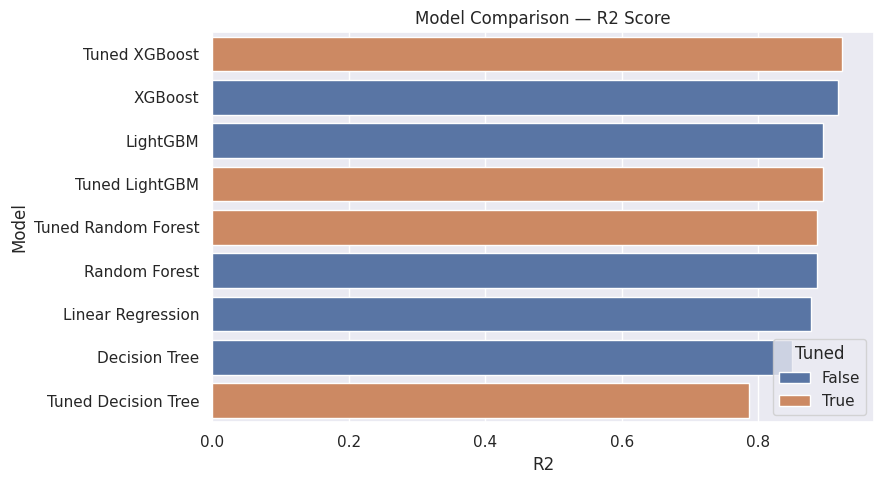

In [ ]:
plt.figure(figsize=(9, 5))
sns.barplot(data=results, x="R2", y="Model", hue="Tuned", dodge=False)
plt.title("Model Comparison — R2 Score")
plt.tight_layout()
plt.show()

# 11. Conclusion

The House Price Prediction project was developed to predict house selling prices using machine learning regression techniques.

The project followed a complete machine learning workflow:

**Data Loading → Data Understanding → Missing Value Treatment → Data Type Correction → Train/Test Split → Exploratory Data Analysis → Feature Engineering → Encoding → Skewness Correction → Scaling → Model Training → Model Evaluation → Hyperparameter Tuning → Model Comparison**

Multiple regression models were trained and compared.

Among the evaluated models, **Tuned XGBoost** achieved the best performance with:

* **MAE:** $14,593.53
* **RMSE:** $24,218.54
* **R² Score:** 0.9235

The model was selected based on its lower prediction errors and higher R² score.

This project demonstrates the application of data preprocessing, exploratory data analysis, feature engineering, model building, evaluation, and hyperparameter tuning to solve a real-world regression problem.
